# Лабораторная работа 1
> - **Предмет:** МОСИИ
> - **Студент:** Руденко Андрей Артемович
> - **Группа:** М9125-01.04.02МКТ

**Цель работы:** Рассмотрение на тестовом примере различных алгоритмов машинного обучения.

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

## Датасет и визуализация данных

In [2]:
df = pd.read_csv('data.csv', index_col=0)
df

,x1,x2,y
0,-4.626272,-6.658988,0
1,-7.789640,0.262519,0
2,-8.739678,1.537758,0
3,-2.546441,-7.705224,0
4,-2.751506,-7.940187,0
...,...,...,...
9995,-3.806339,0.794411,1
9996,3.592259,-1.130786,1
9997,-2.689095,-8.292189,1
9998,-9.470113,2.401624,0


В таблице 10000 объектов и три столбца. `x1` и `x2` это признаки, их можно считать координатами точки на плоскости. `y` это класс объекта, он равен 0 или 1. Модель должна по `x1` и `x2` предсказывать `y`.

<Axes: xlabel='x1', ylabel='x2'>

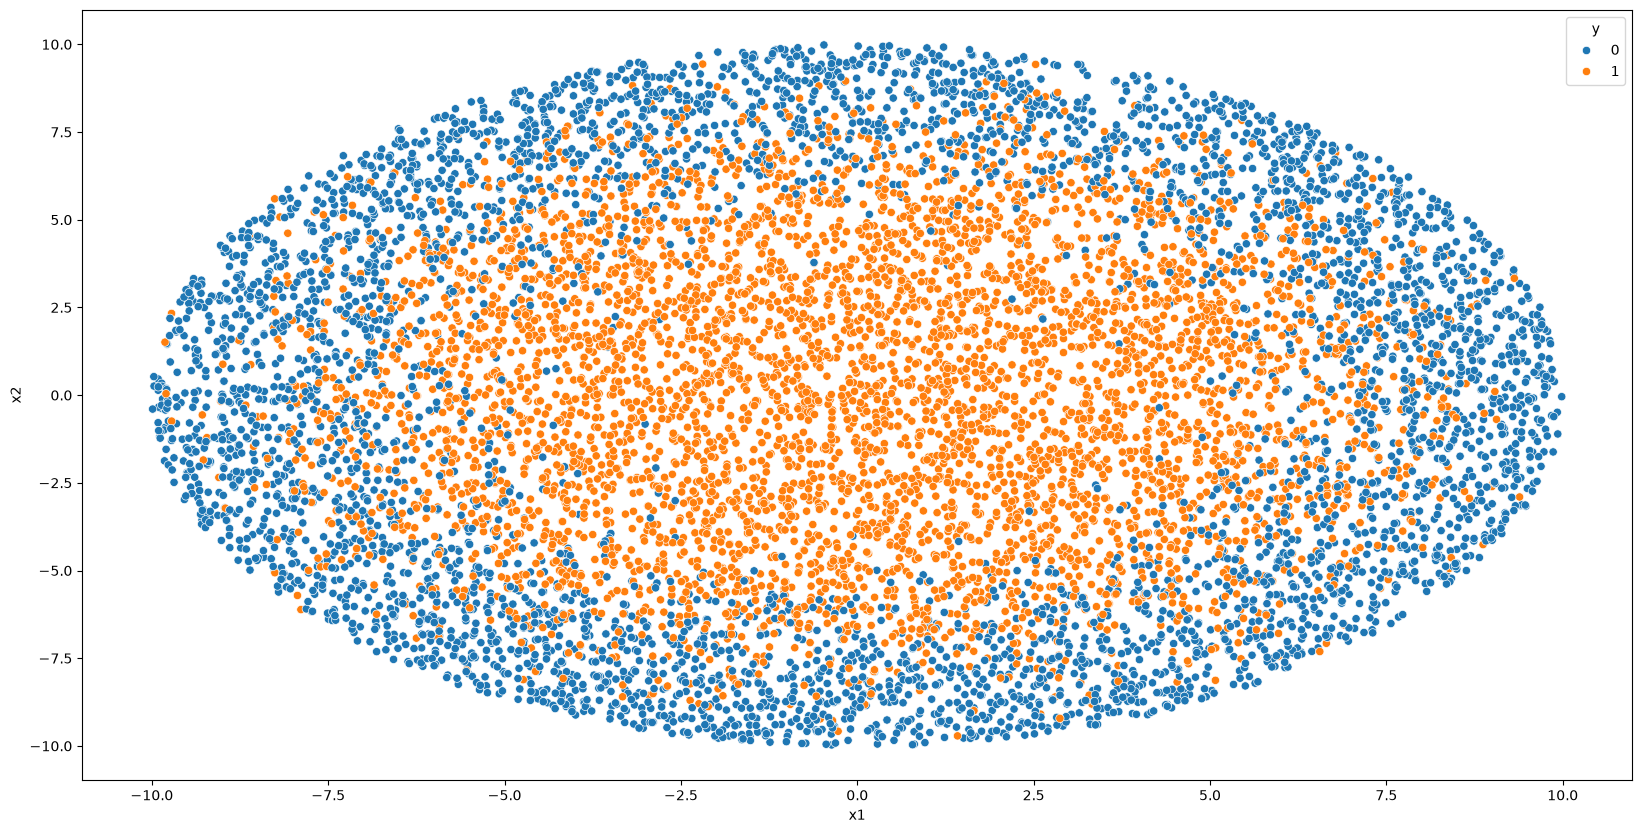

In [3]:
plt.figure(figsize=(20, 10))
sns.scatterplot(x="x1", y="x2", hue="y", data=df)

На графике видно, что классы лежат не по разные стороны друг от друга, а один внутри другого: класс 1 в центре, класс 0 кольцом вокруг. Чёткой границы между ними нет, часть точек одного класса попадает в область другого.

После просмотра данных встает несколько вопросов:
 * 1) `Можем ли мы построить идеальную модель?` Нет. На границе классы перемешаны, и по координатам такие точки не различить, так что ошибки будут у любой модели.
 * 2) `Что ещё мы хотим знать о выборке?` Сколько объектов в каждом классе: если один класс сильно преобладает, accuracy обманчива, потому что модель, которая всегда отвечает самым частым классом, уже получит высокий результат. Это проверим ниже.
 * 3) `Какие алгоритмы можно эффективно использовать?` Граница между классами похожа на окружность, поэтому нужны модели, которые умеют строить нелинейную границу: деревья, случайный лес, нейросеть. Логистической регрессии придётся помогать новыми признаками.

## Логистическая регрессия

Разобьём выборку на train/test.

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

X_train, X_test, y_train, y_test = train_test_split(df[['x1', 'x2']], df['y'], test_size=0.33, random_state=42)

Обучаем логистическую регрессию и получаем от неё два результата на тестовой выборке:
- `predict_logit` - предсказанные классы (0 или 1).
- `predict_log_proba` - вероятность того, что объект относится к классу 1.

Точность нашей модели 0.5960606060606061


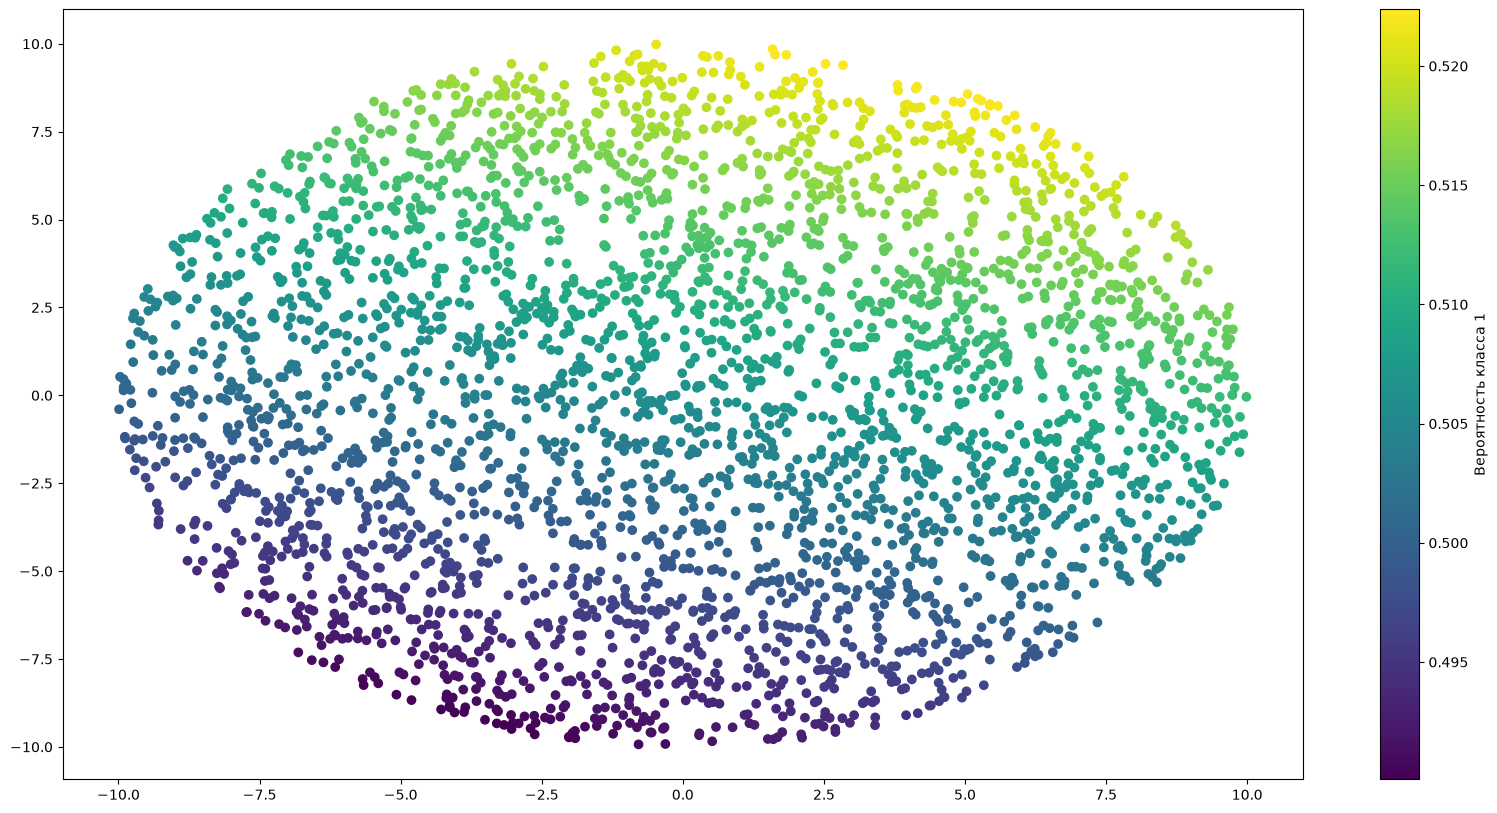

In [5]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression()
model.fit(X_train, y_train)

predict_logit = model.predict(X_test)
predict_log_proba = model.predict_proba(X_test)[:, 1]

print(f'Точность нашей модели {accuracy_score(predict_logit, y_test)}')

# Заодно завизуализируем полученные результаты
plt.figure(figsize=(20, 10))
plt.scatter(X_test['x1'], X_test['x2'], c = predict_log_proba)
plt.colorbar(label='Вероятность класса 1')
plt.show()

Цвет точки на графике показывает вероятность класса 1, которую выдала модель. По легенде видно, что все вероятности лежат примерно от 0.49 до 0.52, то есть модель почти ни в чём не уверена.

Доля правильных ответов получилась 0.60. Чтобы понять, много это или мало, посмотрим, сколько объектов в каждом классе.

In [6]:
cnt = y_test.value_counts()
print(cnt)
print(f'Доля самого частого класса: {cnt.max() / cnt.sum():.3f}')

y
1    1706
0    1594
Name: count, dtype: int64
Доля самого частого класса: 0.517


Классов почти поровну: 1706 объектов класса 1 и 1594 объекта класса 0. Доля самого частого класса примерно 0.52.

> Если всегда предсказывать самый частый класс, доля правильных ответов составит 0.52. Логистическая регрессия даёт 0.60, то есть работает ненамного лучше.

## Обработка данных. Логистическая регрессия V2

Из первого графика видно, что объекты класса 1 расположены ближе к началу координат, а объекты класса 0 вокруг них, по краям. Прямой такие классы разделить нельзя, поэтому линейная модель работает плохо. Чтобы это исправить, можно добавить новый нелинейный признак расстояния от точки до начала координат.

Расстояние от точки $(x_1, x_2)$ до центра $(c_1, c_2)$ считается по теореме Пифагора:

$$d = \sqrt{(x_1 - c_1)^2 + (x_2 - c_2)^2}$$

По графику центр находится в точке $(0, 0)$, поэтому формула упрощается:

$$d = \sqrt{x_1^2 + x_2^2}$$

Точность нашей модели 0.8409090909090909


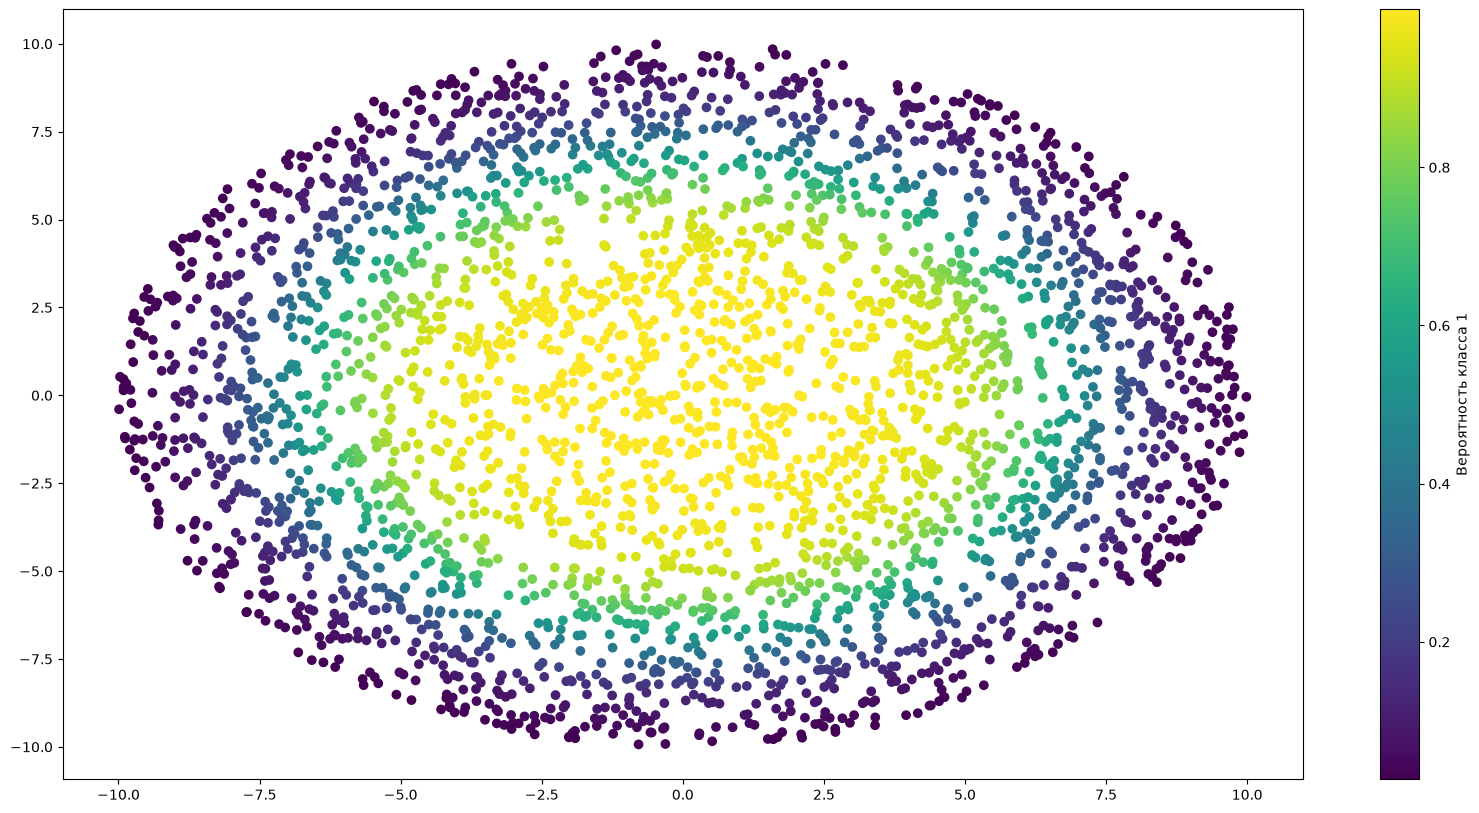

In [7]:
# Повторяем наш код, только с новыми фичами - смотрим на магию
df_new = df.copy()

#########################################
# ваш код для фичей и новой модели

df_new['new_feature_1'] = (df_new['x1']** 2 + df_new['x2'] ** 2) ** 0.5


X_train_new, X_test_new, y_train_new, y_test_new = train_test_split(df_new[['x1', 'x2', 'new_feature_1']],
                                                                    df_new['y'], test_size = 0.33, random_state=42)
model_new = LogisticRegression()
model_new.fit(X_train_new, y_train_new)

predict_logit_new = model_new.predict(X_test_new)
predict_log_proba_new = model_new.predict_proba(X_test_new)[:, 1]

#########################################

print(f'Точность нашей модели {accuracy_score(predict_logit_new,y_test_new)}')

plt.figure(figsize=(20, 10))
plt.scatter(X_test_new['x1'], X_test_new['x2'], c = predict_log_proba_new)
plt.colorbar(label='Вероятность класса 1')
plt.show()

> После добавления нового признака доля правильных ответов выросла с 0.60 до 0.84.

На графике цвет теперь меняется кольцами от центра к краям: в центре вероятность класса 1 высокая, по краям низкая. Это совпадает с тем, как классы расположены на самом деле.

Без ошибок модель всё равно не работает: как видно на первом графике, у границы классы перемешаны, и такие точки по расстоянию до центра не различить.

## Вывод работы логистической регрессии

Логистическая регрессия на исходных признаках `x1` и `x2` даёт долю правильных ответов 0.60, а если всегда предсказывать самый частый класс, получится 0.52. Причина в том, что модель линейная, а классы расположены один внутри другого и прямой не разделяются.

После добавления одного признака, расстояния до начала координат, та же модель даёт 0.84. То есть результат зависит не только от алгоритма, но и от того, в каком виде ему поданы данные.

## Дерево решений

`Какая особенность есть у деревьев? Какой параметр надо зафиксировать, чтобы эта особенность не испортила обучение?`

Дерево склонно к переобучению: без ограничений оно запоминает трейн вместе с перемешанными точками на границе. Поэтому фиксируем глубину `max_depth`. Подбираю её кросс-валидацией на обучающей выборке, тестовая в подборе не участвует, иначе оценка на ней получится завышенной.

In [8]:
from sklearn.model_selection import GridSearchCV
from sklearn.tree import DecisionTreeClassifier

tree_grid = GridSearchCV(DecisionTreeClassifier(random_state=42),
                         {'max_depth': list(range(2, 16))}, cv=5, scoring='accuracy')
tree_grid.fit(X_train, y_train)
best_depth = tree_grid.best_params_['max_depth']
print(f'Лучшая глубина: {best_depth}, accuracy на кросс-валидации: {tree_grid.best_score_:.3f}')

Лучшая глубина: 7, accuracy на кросс-валидации: 0.825


Точность нашей модели 0.8190909090909091


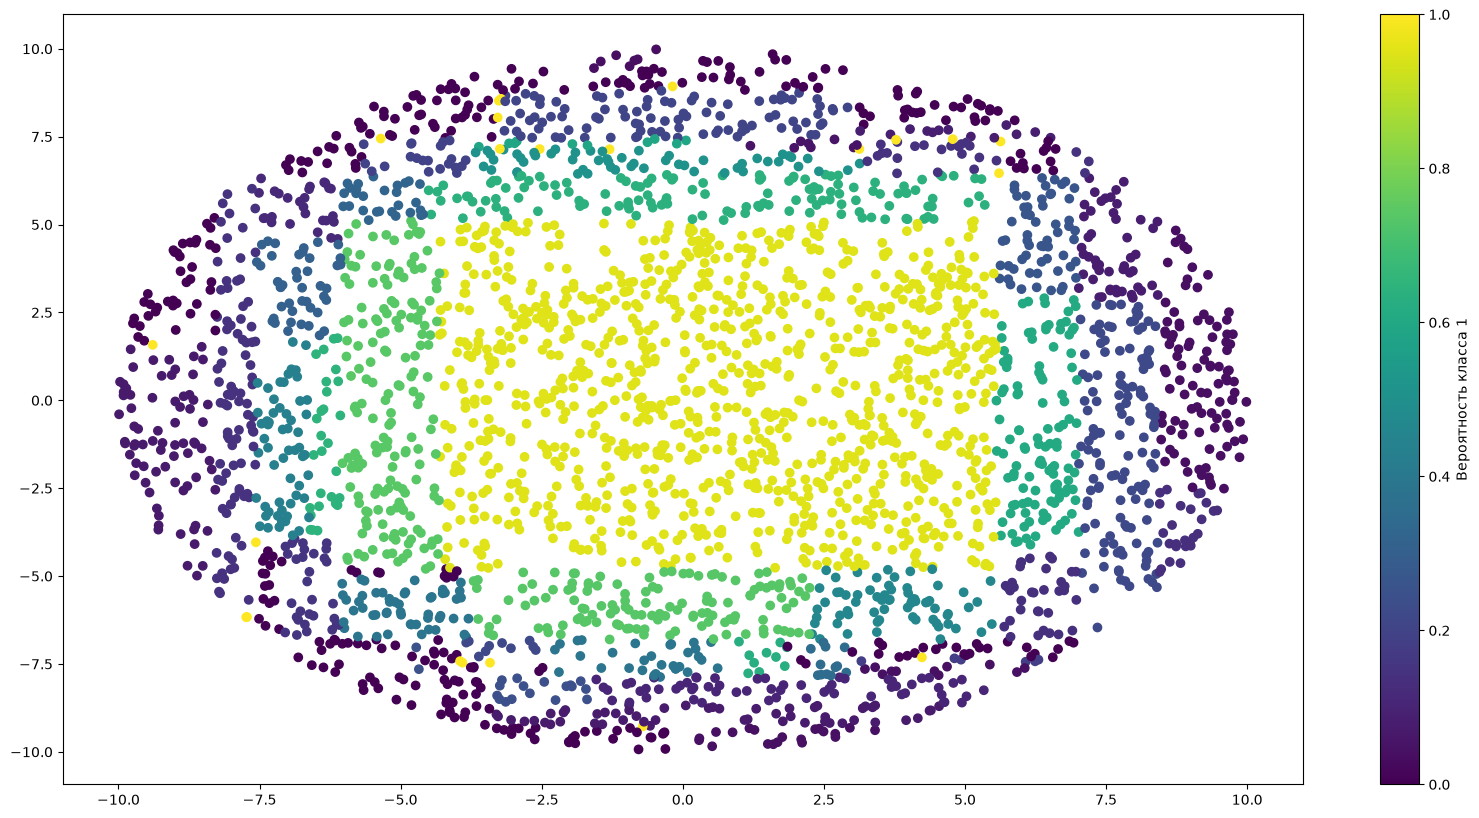

In [9]:
#########################################
# Ваш код

tree = DecisionTreeClassifier(max_depth=best_depth, random_state=42)
tree.fit(X_train, y_train)

predict_tree = tree.predict(X_test)
print(f'Точность нашей модели {accuracy_score(predict_tree, y_test)}')

predict_tree_proba = tree.predict_proba(X_test)[:, 1]

#########################################

plt.figure(figsize=(20,10))
plt.scatter(X_test['x1'], X_test['x2'], c = predict_tree_proba)
plt.colorbar(label='Вероятность класса 1')
plt.show()

## Вывод работы дерева решений

Кросс-валидация выбрала глубину 7, на тесте дерево даёт 0.82 на исходных `x1` и `x2`, без нового признака. Глубину пришлось ограничить, чтобы дерево не запоминало перемешанные точки у границы. Круг оно собирает из прямоугольников, потому что делит плоскость только линиями, параллельными осям, поэтому граница получается ступенчатой.

## Случайный лес

`Поможет ли в данном случае ансамблирование? Когда в целом ансамбль дает хорошие результаты?`

Ансамбль хорош, когда модели в нём разные и ошибаются в разных местах, тогда при голосовании ошибки компенсируют друг друга. Деревья в лесе учатся на разных подвыборках, поэтому лес должен помочь, но немного: перемешанные точки на границе он тоже не угадает. Глубину деревьев в лесе подбираю так же, кросс-валидацией.

In [10]:
from sklearn.ensemble import RandomForestClassifier

forest_grid = GridSearchCV(RandomForestClassifier(n_estimators=100, random_state=42),
                           {'max_depth': [4, 6, 8, 10, 12]}, cv=5, scoring='accuracy')
forest_grid.fit(X_train, y_train)
best_forest_depth = forest_grid.best_params_['max_depth']
print(f'Лучшая глубина: {best_forest_depth}, accuracy на кросс-валидации: {forest_grid.best_score_:.3f}')

Лучшая глубина: 10, accuracy на кросс-валидации: 0.833


Точность нашей модели 0.8348484848484848


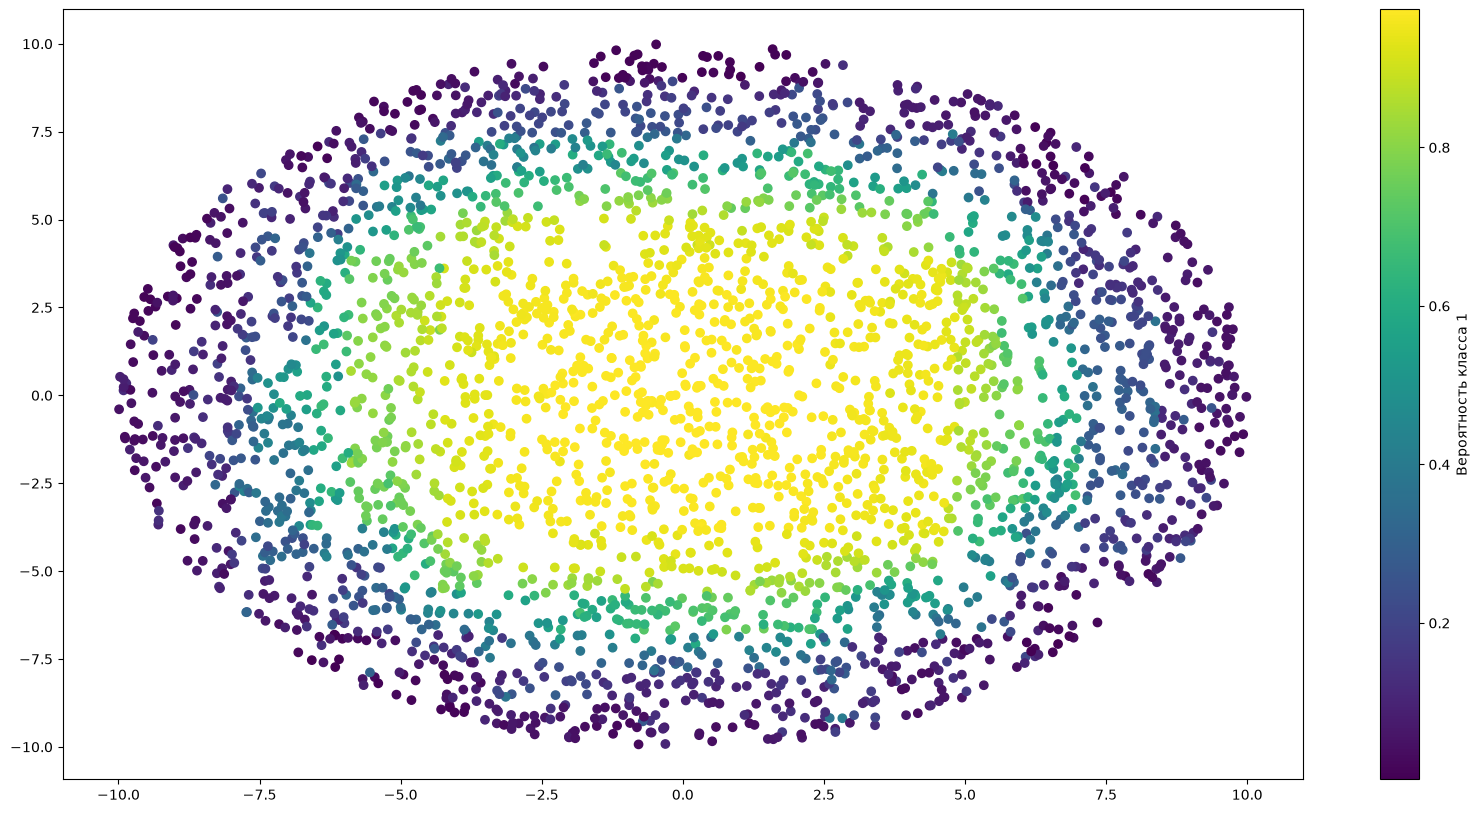

In [11]:
#########################################
# Ваш код

forest = RandomForestClassifier(n_estimators=100, max_depth=best_forest_depth, random_state=42)
forest.fit(X_train, y_train)

predict_forest = forest.predict(X_test)
print(f'Точность нашей модели {accuracy_score(predict_forest, y_test)}')

predict_forest_proba = forest.predict_proba(X_test)[:, 1]

#########################################

plt.figure(figsize=(20, 10))
plt.scatter(X_test['x1'], X_test['x2'], c = predict_forest_proba)
plt.colorbar(label='Вероятность класса 1')
plt.show()

## Вывод работы случайного леса

Для леса кросс-валидация выбрала глубину 10, больше, чем для одного дерева: усреднение по многим деревьям само сглаживает переобучение. Лес даёт 0.835 против 0.82 у одного дерева, граница стала плавнее. Ансамбль помог, но немного: ошибки остаются на перемешанных точках у границы.

## Нейронная сеть

Простая сеть: два скрытых слоя по 5 нейронов и 2 выхода, по одному на класс. Обучаю 100 эпох с Adam и `lr = 1e-3`: к концу обучения loss почти перестаёт падать.

In [12]:
import torch
import torch.nn as nn
import torch.optim as optim
import torch.utils.data as data_utils

torch.manual_seed(42)

INPUT_SIZE = 2
HIDDEN_SIZE = 5
OUTPUT_SIZE = 2
LEARNING_RATE = 1e-3
EPOCHS = 100
BATCH_SIZE = 128

train_tensor = data_utils.TensorDataset(torch.tensor(X_train.values.astype(np.float32)), torch.tensor(y_train.values))
train_loader = data_utils.DataLoader(dataset=train_tensor, batch_size=BATCH_SIZE, shuffle=True)

nn_model = nn.Sequential(
    nn.Linear(in_features=INPUT_SIZE, out_features=HIDDEN_SIZE),
    nn.Sigmoid(),
    nn.Linear(in_features=HIDDEN_SIZE, out_features=HIDDEN_SIZE),
    nn.Sigmoid(),
    nn.Linear(in_features=HIDDEN_SIZE, out_features=OUTPUT_SIZE),
)

optimizer = optim.Adam(nn_model.parameters(), lr=LEARNING_RATE)
criterion = nn.CrossEntropyLoss()

for epoch in range(EPOCHS):
    nn_model.train()
    running_loss = []
    for features, label in train_loader:
        optimizer.zero_grad()
        loss = criterion(nn_model(features), label)
        loss.backward()
        optimizer.step()
        running_loss.append(loss.item())
    if epoch % 20 == 0:
        print(f'Эпоха {epoch}: loss {np.mean(running_loss):.4f}')

Эпоха 0: loss 0.6926
Эпоха 20: loss 0.6549
Эпоха 40: loss 0.4553
Эпоха 60: loss 0.3851
Эпоха 80: loss 0.3717


Точность нашей модели 0.8390909090909091


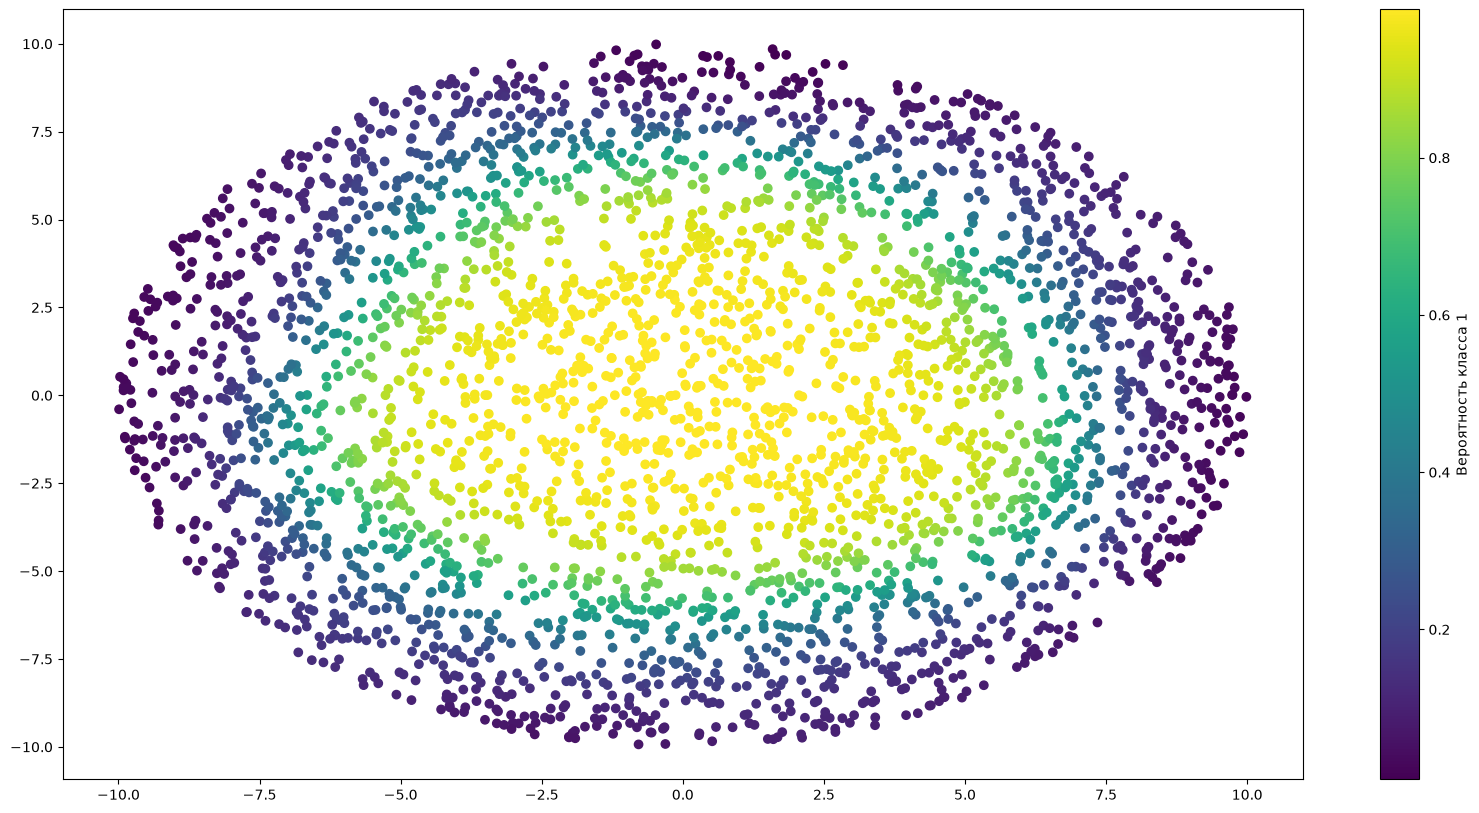

In [13]:
#########################################
# Ваш код

nn_model.eval()
with torch.no_grad():
    test_scores = nn_model(torch.tensor(X_test.values.astype(np.float32)))

predict_neural = torch.softmax(test_scores, dim=1)[:, 1].numpy()
predict_classes = torch.argmax(test_scores, dim=1).numpy()

print(f'Точность нашей модели {accuracy_score(predict_classes, y_test)}')
#########################################

plt.figure(figsize=(20, 10))
plt.scatter(X_test['x1'], X_test['x2'], c = predict_neural)
plt.colorbar(label='Вероятность класса 1')
plt.show()

## Вывод работы нейронной сети

Нейросеть даёт 0.84, как логистическая регрессия с новым признаком, но круглую границу она нашла сама по `x1` и `x2`.

## Технический отчёт

| Модель | Признаки | Accuracy |
|---|---|---|
| Всегда самый частый класс | — | 0.52 |
| Логистическая регрессия (baseline) | `x1`, `x2` | 0.60 |
| Логистическая регрессия | `x1`, `x2`, расстояние до центра | 0.84 |
| Дерево решений, `max_depth=7` | `x1`, `x2` | 0.82 |
| Случайный лес, 100 деревьев, `max_depth=10` | `x1`, `x2` | 0.835 |
| Нейросеть 2×5 | `x1`, `x2` | 0.84 |

Baseline почти не лучше угадывания: логистическая регрессия строит только прямую. Перебить его получилось двумя путями: добавить признак «расстояние до центра» или взять модель, которая сама строит нелинейную границу (дерево, лес, нейросеть).

Лучшие модели упираются примерно в 0.84. Видимо, это потолок для этих данных из-за перемешанных точек на границе. Логистическая регрессия с удачным признаком работает не хуже нейросети, но форму границы для неё пришлось угадать самому, а лес и нейросеть находят её сами.